# 1.5.6 Multilayer Perceptron

For multiclass classification using numerical differentiation for finding approximate gradient and gradient decent.

Uses:

- Cross entropy loss function
- ReLU activation function in hidden layers
- Soft max activation function in the output layer
- ArgMax for class index identification

Process:

- The dataset target values are one hot encoded
- if we set proba = true then the output will be the predicted probability
- if we set proba = false then the output will be the Argmax class index

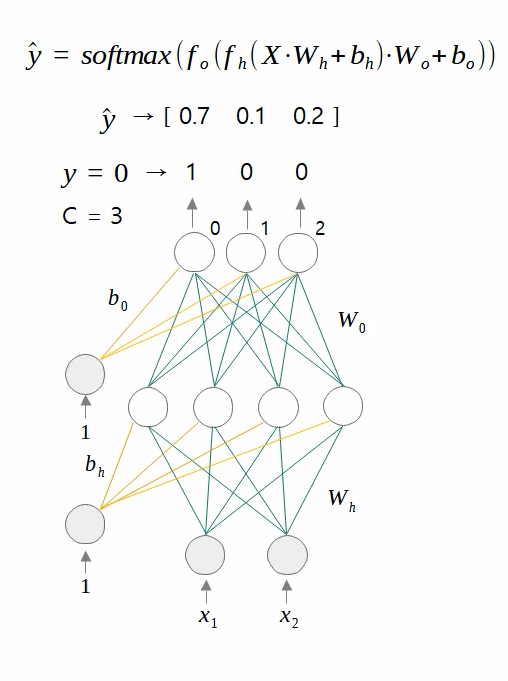

In [1]:
%load_ext autoreload
%autoreload 2
from gradient_descent import gradient_descent # my python file

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

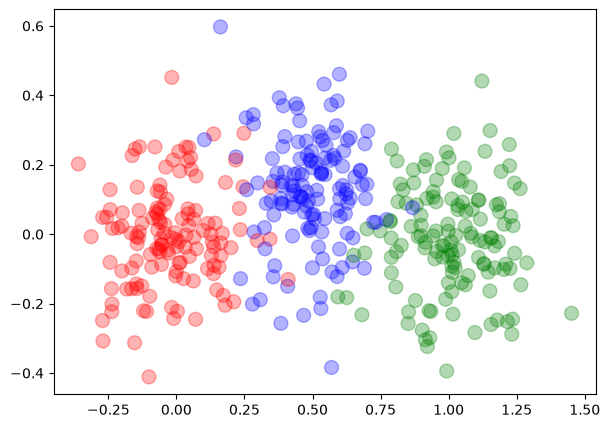

In [2]:
# Generate a dataset for multiclass classification
x, y = make_blobs(n_samples=400, n_features=2,
                  centers=[[0., 0.], [0.5, 0.1], [1., 0.]],
                  cluster_std=0.15, center_box=(-1., 1.))

n_class = np.unique(y).shape[0]  # the number of classes

# See the data visually.
plt.figure(figsize=(7,5))
color = [['red', 'blue', 'green'][a] for a in y.reshape(-1,)]
plt.scatter(x[:, 0], x[:, 1], s=100, c=color, alpha=0.3)
plt.show()

## One hot encoding the target

In [3]:
# one-hot encode class y, y = [0,1,2]
y_ohe = np.eye(n_class)[y]

In [4]:
# Generate the training and test data
x_train, x_test, y_train, y_test = train_test_split(x, y_ohe)

# Create a two-layered ANN model.
n_input = x.shape[1]   # number of input neurons
n_output = n_class     # number of output neurons
n_hidden = 16          # number of hidden neurons
alpha = 0.05           # learning rate
h = 1e-4               # constant for numerical differentiation

# initialize the parameters randomly.
wh = np.random.normal(size=(n_input, n_hidden))
bh = np.zeros(shape=(1, n_hidden))
wo = np.random.normal(size=(n_hidden, n_output))
bo = np.zeros(shape=(1, n_output))
parameters = [wh, bh, wo, bo]

In [5]:
# activation functions
def softmax(x):
    A = np.max(x, axis=1, keepdims=True)
    e = np.exp(x - A)
    return e / np.sum(e, axis=1, keepdims=True)

def relu(x):
    return np.maximum(0, x)

In [6]:
# loss function: categorical cross entropy
def loss(y, y_hat):
    ce = -np.sum(y * np.log(y_hat), axis=1)
    return np.mean(ce)

# Output from the ANN model: prediction process
def predict(x, proba=True):
    p = parameters
    o_hidden = relu(np.dot(x, p[0]) + p[1])
    o_output = softmax(np.dot(o_hidden, p[2]) + p[3])
    
    if proba:
        return o_output           # return probability distribution
    else:
        return np.argmax(o_output, axis=1)  # return class

# Perform training and track the loss history.
def train(x, y, x_val, y_val, epochs, batch_size):
    ht_loss = []    # loss history of training data
    hv_loss = []    # loss history of test data
    for epoch in range(epochs):
        # measure the losses during training
        ht_loss.append(loss(y, predict(x)))       # train loss
        hv_loss.append(loss(y_val, predict(x_val))) # validation
                                                    # loss
        # Perform training using mini-batch gradient descent
        for batch in range(int(x.shape[0] / batch_size)):
            idx = np.random.choice(x.shape[0], batch_size)
            gradient_descent(x[idx], y[idx], alpha, loss,
                             predict, parameters)

        if epoch % 10 == 0:
            print("{}: train_loss={:.4f}, val_loss={:.4f}".\
                  format(epoch, ht_loss[-1], hv_loss[-1]))
            
    return ht_loss, hv_loss

# Perform training
train_loss, val_loss = train(x_train, y_train, x_test, y_test,
                             epochs=200, batch_size=50)

0: train_loss=1.2212, val_loss=1.2979
10: train_loss=0.5044, val_loss=0.5279
20: train_loss=0.3515, val_loss=0.3719
30: train_loss=0.2784, val_loss=0.2964
40: train_loss=0.2350, val_loss=0.2515
50: train_loss=0.2104, val_loss=0.2301
60: train_loss=0.1930, val_loss=0.2159
70: train_loss=0.1801, val_loss=0.2055
80: train_loss=0.1700, val_loss=0.1948
90: train_loss=0.1621, val_loss=0.1836
100: train_loss=0.1561, val_loss=0.1815
110: train_loss=0.1498, val_loss=0.1765
120: train_loss=0.1459, val_loss=0.1666
130: train_loss=0.1409, val_loss=0.1693
140: train_loss=0.1374, val_loss=0.1666
150: train_loss=0.1347, val_loss=0.1680
160: train_loss=0.1323, val_loss=0.1610
170: train_loss=0.1309, val_loss=0.1575
180: train_loss=0.1278, val_loss=0.1605
190: train_loss=0.1265, val_loss=0.1676


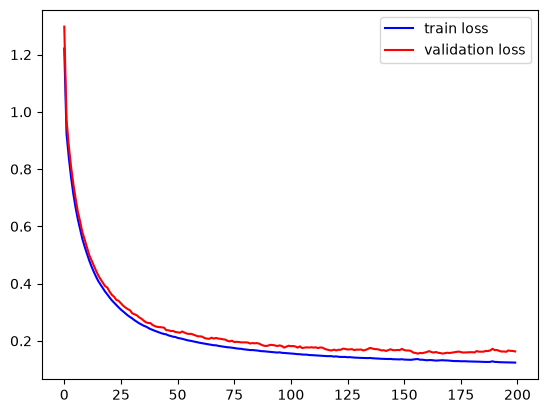

In [7]:
# Visually check the loss history.
plt.plot(train_loss, c='blue', label='train loss')
plt.plot(val_loss, c='red', label='validation loss')
plt.legend()
plt.show()

In [8]:
# Check the accuracy.
y_pred = predict(x_train, proba=False)
acc = (y_pred == np.argmax(y_train, axis=1)).mean()
print("Accuracy of training data = {:.4f}".format(acc))

y_pred = predict(x_test, proba=False)
acc = (y_pred == np.argmax(y_test, axis=1)).mean()
print("Accuracy of the test data = {:4f}".format(acc))

Accuracy of training data = 0.9600
Accuracy of the test data = 0.940000


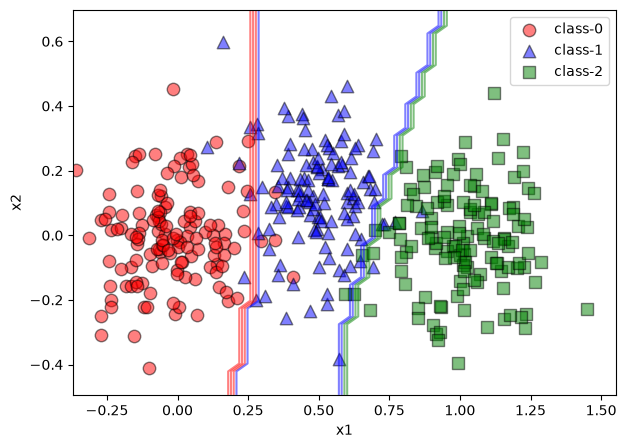

In [9]:
# Visualize the decision boundaries.
# reference :
# https://psrivasin.medium.com/
#  plotting-decision-boundaries-using-numpy-and-matplotlib-
#  f5613d8acd19
x_min, x_max = x_test[:, 0].min() - 0.1, x_test[:, 0].max() + 0.1
y_min, y_max = x_test[:, 1].min() - 0.1, x_test[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 50),
                     np.linspace(y_min, y_max, 50))
x_in = np.c_[xx.ravel(), yy.ravel()]

# Predict the classes of the data points in the x_in variable.
y_pred = predict(x_in, proba=False).astype('int8')
y_pred = y_pred.reshape(xx.shape)

plt.figure(figsize=(7, 5))
m = ['o', '^', 's']
color = ['red', 'blue', 'green']
for i in [0, 1, 2]:
    idx = np.where(y == i)
    plt.scatter(x[idx, 0], x[idx, 1],
                c = color[i],
                marker = m[i],
                s = 80,
                edgecolor = 'black',
                alpha = 0.5,
                label='class-' + str(i))

plt.contour(xx, yy, y_pred, cmap=ListedColormap(color), alpha=0.5)
plt.axis('tight')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()